# ****DATA UNDERSTANDING****

<p align="center">
    <img src="../xLain-Lain/img/du_1.png" alt="Pendahuluan" witdh="100" height="500">
</p>

### ****DAFTAR ISI****

1. Persiapan dan Pemuatan Data
2. Struktur, Tipe, dan Statistik Deskriptif
3. Audit Kalender dan Missing Value
4. Audit Stale Price
5. Verifikasi Definisi Target $Y$ dan Jebakan Kebocoran Lag
6. Audit Anomali Data
7. Frekuensi Pembaruan Variabel Makro
8. Distribusi dan Dinamika Target
9. Volatility Clustering
10. Sinyal Awal Antara Kandidat Prediktor dan Target
11. Stasioneritas
12. Pergeseran Rezim: Data Latih vs Data Uji
13. Ringkasan Temuan dan Decision Log

---

### ****1. Persiapan dan Pemuatan Data****

Sel ini memuat pustaka dan membaca data mentah. Kolom Date dibaca sebagai *datetime* dan dijadikan indeks agar operasi deret waktu (rolling, shift) berbasis tanggal. Dua konstanta penting didefinisikan di sini dan dipakai di seluruh notebook kami ini adalah:

- TRAIN_END = 2024-12-3: batas data berlabel. Seluruh baris sejak 2025 adalah data uji (tanpa $Y$).
- PRICE_COLS dan MACRO_COLS: pemisahan variabel pasar harian dan variabel makro berfrekuensi rendah.

In [1]:
# muat pustaka

import warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import statsmodels
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [3]:
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# sekadar informasi kalau tim kami memang sudah ada format pengerjaan dan framework tersendiri, jadinya ini boleh diabaikan karena hanya
# pendefinisian path saja... 

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, cwd.parent] if (p / "Dataset").exists()), cwd)
RAW_DIR, CLEAN_DIR = ROOT / "Dataset" / "Raw", ROOT / "Dataset" / "Clean"
IMG_DIR, NOTE_DIR = ROOT / "xLain-Lain" / "img", ROOT / "Catatan"
for d in (CLEAN_DIR, IMG_DIR, NOTE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# gaya visual

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = "#2F6DB5", "#E8833A", "#3E9B5F", "#C0392B", "#7B5EA7", "#8A8F98"

def save_fig(fig, name):
    fig.savefig(IMG_DIR / name, bbox_inches="tight", facecolor="white")
    print(f"Gambar disimpan: xLain-Lain/img/{name}")

# Konstanta proyek

TARGET = "Target_Volatilitas_Y"
PRICE_COLS = ["OIL", "GOLD", "USDIDR", "SP500", "IHSG", "VIX"]
MACRO_COLS = ["CPI", "BI_rate", "US_rate"]
TRAIN_END = pd.Timestamp("2024-12-31")
TEST_START = pd.Timestamp("2025-01-01")

# muat raw data

DATA_PATH = next(p for p in [RAW_DIR / "dataset peserta.csv", RAW_DIR / "dataset_peserta.csv"] if p.exists())
df = pd.read_csv(DATA_PATH, parse_dates=["Date"]).sort_values("Date").set_index("Date")

y = df[TARGET]
is_lab = y.notna()
print(f"Berkas : {DATA_PATH.relative_to(ROOT)}")
print(f"Dimensi : {df.shape[0]:,} baris x {df.shape[1]} kolom | {df.index.min():%Y-%m-%d} s.d. {df.index.max():%Y-%m-%d}")
# print(f"pandas {pd.__version__} | numpy {np.__version__} | statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__}")

Berkas : Dataset\Raw\dataset_peserta.csv
Dimensi : 4,266 baris x 10 kolom | 2010-01-04 s.d. 2026-05-22


### ****2. Struktur, Tipe, dan Statistik Deskriptif****

Tujuannya adalah memastikan tipe data benar dan mendapatkan gambaran awal skala dan sebaran tiap variabel. Statistik deskriptif ditampilkan dengan persentil (1%, 5%, 25%, 50%, 75%, 95%, 99%) karena rata-rata dan simpangan baku saja menyembunyikan ekor distribusi, yang justru bagian terpenting pada data keuangan. Data uji (2025+) tidak diikutkan agar gambaran ini murni berasal dari data latih.

In [4]:
print("Contoh Baris Awal dan Akhir:")
display(pd.concat([df.head(3), df.tail(3)]).style.format("{:,.4f}"))

info = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unik": df.nunique(),
    "min": df.min(), "max": df.max(),
})

print("\nTipe, Kelengkapan, dan Jumlah Nilai Unik:")
display(info.style.format({"min": "{:,.4f}", "max": "{:,.4f}"}))

desc = df.loc[:TRAIN_END].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = df.loc[:TRAIN_END].skew()
desc["kurt"] = df.loc[:TRAIN_END].kurt()

print("\nStatistik Deskriptif Data Latih (2010-2024):")
display(desc.drop(columns="count").style.format("{:,.4f}"))

Contoh Baris Awal dan Akhir:


,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
Date,,,,,,,,,,
2010-01-04 00:00:00,81.5100,"1,117.7000","9,364.2002","1,132.9900","2,575.3130",20.0400,5.1342,6.5000,0.1100,0.0077
2010-01-05 00:00:00,81.7700,"1,118.1000","9,305.2002","1,136.5200","2,605.1755",19.3500,5.1342,6.5000,0.1100,0.0074
2010-01-06 00:00:00,83.1800,"1,135.9000","9,218.0996","1,137.1400","2,603.1956",19.1600,5.1342,6.5000,0.1100,0.0098
2026-05-20 00:00:00,98.2600,"4,531.2998","17,777.0000","7,432.9702","6,318.5000",17.4400,3.5500,5.2500,3.6300,nan
2026-05-21 00:00:00,96.3500,"4,539.7998","17,658.4004","7,445.7202","6,094.9409",16.7600,3.5500,5.2500,3.6300,nan
2026-05-22 00:00:00,96.6000,"4,521.0000","17,692.0000","7,473.4702","6,162.0449",16.7000,3.5500,5.2500,3.6300,nan



Tipe, Kelengkapan, dan Jumlah Nilai Unik:


,tipe,non_null,n_unik,min,max
OIL,float64,4266,3207,-37.6300,123.7000
GOLD,float64,4266,3360,"1,050.8000","5,318.3999"
USDIDR,float64,4266,3431,888.1100,"17,777.0000"
SP500,float64,4266,4100,"1,022.5800","7,501.2402"
IHSG,float64,4266,3968,"2,475.4756","9,134.7002"
VIX,float64,4266,1764,9.1400,82.6900
CPI,float64,4266,17,0.7600,6.4125
BI_rate,float64,4266,18,3.5000,7.7500
US_rate,float64,4266,81,0.0500,5.3300
Target_Volatilitas_Y,float64,3907,3871,0.0000,0.0585



Statistik Deskriptif Data Latih (2010-2024):


,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurt
OIL,71.9864,21.3610,-37.6300,26.0878,39.7730,53.2800,73.0400,89.4050,104.4170,111.0260,123.7000,-0.1098,-0.7551
GOLD,"1,543.4419",349.2635,"1,050.8000","1,078.5440","1,140.7400","1,259.8000","1,434.5000","1,784.1000","2,182.4700","2,644.7940","2,788.5000",0.9795,0.7005
USDIDR,"12,825.2044","2,341.0874",888.1100,"8,523.1302","8,870.4151","11,180.0000","13,540.0000","14,492.0000","15,714.8500","16,246.0000","16,504.8008",-0.6692,-0.6977
SP500,"2,724.8586","1,260.8390","1,022.5800","1,076.8320","1,166.6410","1,700.2550","2,429.3899","3,810.4950","5,117.6849","5,842.4102","6,090.2700",0.6549,-0.5599
IHSG,"5,401.0160","1,229.7807","2,475.4756","2,626.6938","3,380.9444","4,479.2917","5,381.7876","6,382.4089","7,225.2121","7,563.0458","7,905.3901",-0.2222,-0.8055
VIX,18.3491,6.9366,9.1400,9.8200,11.2830,13.5700,16.5900,21.1400,31.4540,41.2452,82.6900,2.3521,10.7616
CPI,4.0705,1.5468,1.5601,1.5601,1.5601,3.0306,3.8088,5.3560,6.4125,6.4125,6.4125,0.1139,-1.0558
BI_rate,5.6744,1.2555,3.5000,3.5000,3.5000,4.7500,5.7500,6.5000,7.5000,7.7500,7.7500,-0.1817,-0.9187
US_rate,1.2265,1.7109,0.0500,0.0500,0.0700,0.0900,0.1900,1.8200,5.3300,5.3300,5.3300,1.4757,0.7775
Target_Volatilitas_Y,0.0083,0.0056,0.0000,0.0015,0.0027,0.0049,0.0071,0.0100,0.0190,0.0289,0.0585,2.6370,12.2298


>INTERPRETASI

1. Struktur bersih secara teknis. Seluruh sepuluh kolom bertipe float64, tanpa nilai kosong pada fitur. Kolom $Y$ terisi 3.907 dari 4.266 baris dan 359 baris sisanya adalah data uji.
2. Tiga variabel makro berfrekuensi sangat rendah. CPI hanya memiliki 17 nilai unik, BI_rate 18, dan US_rate 81 dari 4.266 hari. Ini bukan data harian sungguhan.
3. Dua nilai mencurigakan sudah tampak dari rentang saja. USDIDR bernilai minimum 888,11 padahal kurs berada di kisaran 8.000-17.000, dan OIL bernilai minimum -37,63.
4. Target condong ke kanan dan berekor berat. Rata-rata $Y$ = 0,0083, median 0,0071, *skewness* 2,64, dan kurtosis berlebih 12,2. Nilai tengah dan ekor sangat berbeda dimana persentil ke-99 (0,0289) hampir empat kali rata-ratanya. Hal serupa terjadi pada VIX (*skewness* 2,35, kurtosis 10,8), yang wajar karena keduanya adalah ukuran gejolak.
5. Rentang level data latih jauh lebih sempit daripada data keseluruhan. Misalnya GOLD pada data latih berkisar 1.051-2.789, sedangkan seluruh dataset mencapai 5.318.

### ****3. Audit Kalender dan Data Hilang****

Mengapa? Seluruh operasi deret waktu (kayak rolling(5) atau shift) mengasumsikan bahwa baris berurutan merepresentasikan hari perdagangan yang berurutan. Bila ada hari yang hilang atau tanggal ganda, jendela "5 hari" tidak lagi bermakna 5 hari kalender kerja. Pemeriksaan ini juga menentukan apakah data berisi hari perdagangan saja atau seluruh hari kerja (Senin-Jumat).

In [5]:
full_bdays = pd.bdate_range(df.index.min(), df.index.max())
missing_bdays = full_bdays.difference(df.index)

print(f"Hari Kerja (Senin-Jumat) yang Seharusnya Ada : {len(full_bdays):,}")
print(f"Baris Pada Dataset : {len(df):,}")
print(f"Hari Kerja yang Tidak Ada pada Dataset : {len(missing_bdays):,}")
print(f"Tanggal Duplikat : {df.index.duplicated().sum()}")
print(f"Total Nilai Kosong pada Fitur X : {int(df.drop(columns=TARGET).isna().sum().sum())}")

gap = df.index.to_series().diff().dt.days.dropna().astype(int)
gap_tbl = gap.value_counts().sort_index().rename_axis("selisih_hari_kalender").to_frame("jumlah")
gap_tbl["arti"] = gap_tbl.index.map({1: "hari kerja berurutan", 2: "ada 1 hari kerja hilang (mis. Sel/Rab/Kam)", 3: "akhir pekan biasa (Jum -> Sen)", 4: "ada 1 hari kerja hilang di sekitar akhir pekan"}).fillna("celah panjang")
print("\nDistribusi Selisih Tanggal Antar Baris:")
display(gap_tbl)

print("\nHari Kerja yang Hilang (dengan baris sebelum dan sesudahnya):")
ctx = []
for d in missing_bdays:
    prev_d = df.index[df.index < d].max(); next_d = df.index[df.index > d].min()
    ctx.append({"hari_hilang": d.date(), "nama_hari": d.day_name(), "baris_sebelum": prev_d.date(), "baris_sesudah": next_d.date()})
display(pd.DataFrame(ctx))

per_year = df.groupby(df.index.year).agg(baris=(TARGET, "size"), Y_ada=(TARGET, "count"))
per_year["Y_kosong"] = per_year["baris"] - per_year["Y_ada"]
print("\nJumlah Baris per Tahun dan Ketersediaan Y:")
display(per_year.T)

Hari Kerja (Senin-Jumat) yang Seharusnya Ada : 4,275
Baris Pada Dataset : 4,266
Hari Kerja yang Tidak Ada pada Dataset : 9
Tanggal Duplikat : 0
Total Nilai Kosong pada Fitur X : 0

Distribusi Selisih Tanggal Antar Baris:


,jumlah,arti
selisih_hari_kalender,,
1,3409,hari kerja berurutan
2,2,ada 1 hari kerja hilang (mis. Sel/Rab/Kam)
3,852,akhir pekan biasa (Jum -> Sen)
4,1,ada 1 hari kerja hilang di sekitar akhir pekan
9,1,celah panjang



Hari Kerja yang Hilang (dengan baris sebelum dan sesudahnya):


,hari_hilang,nama_hari,baris_sebelum,baris_sesudah
0,2024-12-25,Wednesday,2024-12-24,2025-01-02
1,2024-12-26,Thursday,2024-12-24,2025-01-02
2,2024-12-27,Friday,2024-12-24,2025-01-02
3,2024-12-30,Monday,2024-12-24,2025-01-02
4,2024-12-31,Tuesday,2024-12-24,2025-01-02
5,2025-01-01,Wednesday,2024-12-24,2025-01-02
6,2025-04-18,Friday,2025-04-17,2025-04-21
7,2025-12-25,Thursday,2025-12-24,2025-12-26
8,2026-01-01,Thursday,2025-12-31,2026-01-02



Jumlah Baris per Tahun dan Ketersediaan Y:


Date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
baris,260,260,261,261,261,261,261,260,261,261,262,261,260,260,257,258,101
Y_ada,260,260,261,261,261,261,261,260,261,261,262,261,260,260,257,0,0
Y_kosong,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,258,101


>INTERPRETASI

1. Dataset adalah kalender hari kerja yang hampir lengkap, bukan kalender hari bursa. Dari 4.275 hari kerja (Senin-Jumat) pada rentang data, 4.266 ada, atau hanya 9 yang hilang. Tidak ada tanggal ganda dan tidak ada nilai kosong pada fitur. Artinya, hari libur bursa tidak dihapus, melainkan **diisi nilai hari sebelumnya**.
2. Sembilan hari yang hilang bukan acak. Enam di antaranya berurutan: 25 Desember 2024 sampai 1 Januari 2025, sehingga ada celah 9 hari kalender antara 24 Desember 2024 dan 2 Januari 2025. Tiga lainnya jatuh pada periode uji: 18 April 2025, 25 Desember 2025, dan 1 Januari 2026. Semuanya berkaitan dengan libur akhir tahun atau libur nasional, ketika sebagian besar pasar tutup.
3. Konsekuensi untuk target. Letak celah terbesar tepat di batas antara data berlabel dan data uji.
4. Konsekuensi untuk fitur. Jendela rolling(5) berbasis baris akan menjangkau lebih dari lima hari kerja bila ada celah.
5. Kelengkapan per tahun wajar. Sekitar 260 baris per tahun; 2024 hanya 257 baris karena celah akhir tahun, dan 2026 baru berisi 101 baris (sampai 22 Mei).

### ****4. Audit Stale Price****

Mengapa? Dataset memuat seluruh hari kerja, padahal bursa Indonesia, bursa AS, dan pasar komoditas memiliki hari libur yang berbeda. Pada hari libur, harga tidak berubah. Bila kolom diisi dengan harga hari sebelumnya (*forward-fill*), *return* hari libur menjadi tepat nol. Hal ini berdampak langsung pada target: simpangan baku dari lima *return* yang sebagian bernilai nol cenderung terlalu kecil, sehingga $Y$ pada pekan berlibur bias ke bawah.

Gimana cara mendeteksinya? Harga indeks bertipe *float* nyaris mustahil persis sama dua hari berturut-turut, sehingga selisih nol hampir pasti menandakan hari libur atau data yang tidak diperbarui. Kami membandingkan frekuensinya antar variabel dan memetakan polanya per tahun dan bulan.

Frekuensi Hari dengan Harga Tidak Berubah (selisih = 0):


,hari_tidak_berubah,persen_dari_total
IHSG,295,6.92%
VIX,167,3.91%
GOLD,162,3.80%
OIL,162,3.80%
SP500,149,3.49%
USDIDR,101,2.37%



Klasifikasi Hari IHSG Tidak Berubah:


,jumlah_hari
"IHSG diam, S&P500 bergerak (libur domestik)",254
"IHSG diam, S&P500 diam (libur bersama / data tidak diperbarui)",41
"IHSG bergerak, S&P500 diam (libur AS)",108


Gambar disimpan: xLain-Lain/img/du_1.png


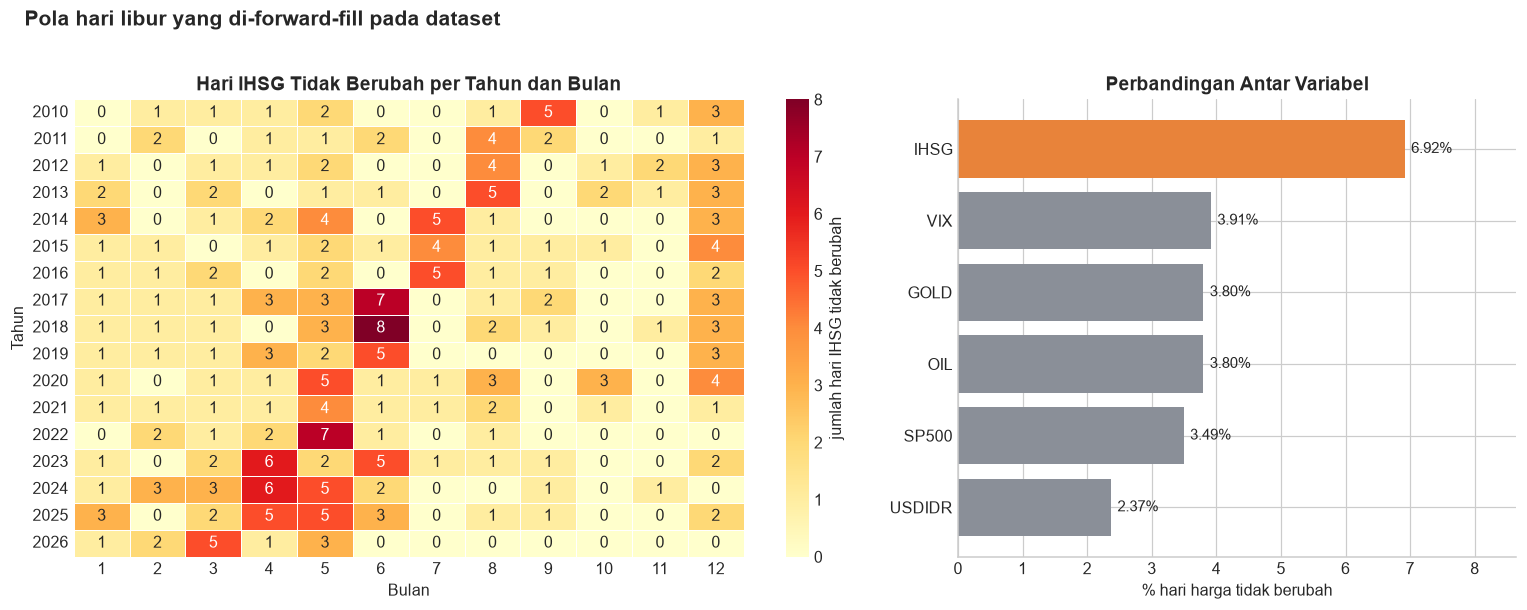

In [8]:
unchanged = df[PRICE_COLS].diff().eq(0) # True bila harga sama dengan hari sebelumnya
stale_tbl = pd.DataFrame({
    "hari_tidak_berubah": unchanged.sum(),
    "persen_dari_total": unchanged.mean() * 100,
}).sort_values("persen_dari_total", ascending=False)
print("Frekuensi Hari dengan Harga Tidak Berubah (selisih = 0):")
display(stale_tbl.style.format({"persen_dari_total": "{:.2f}%"}))

# Klasifikasi: IHSG tidak berubah, dibandingkan dengan S&P 500

ih, sp = unchanged["IHSG"], unchanged["SP500"]
klas = pd.Series({
    "IHSG diam, S&P500 bergerak (libur domestik)": int((ih & ~sp).sum()),
    "IHSG diam, S&P500 diam (libur bersama / data tidak diperbarui)": int((ih & sp).sum()),
    "IHSG bergerak, S&P500 diam (libur AS)": int((~ih & sp).sum()),
}, name="jumlah_hari")
print("\nKlasifikasi Hari IHSG Tidak Berubah:")
display(klas.to_frame())

# heatmap tahun x bulan

heat = pd.crosstab(df.index.year[ih.values], df.index.month[ih.values]).reindex(columns=range(1, 13), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(heat, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={"label": "jumlah hari IHSG tidak berubah"}, linewidths=0.4, ax=axes[0])
axes[0].set_xlabel("Bulan"); axes[0].set_ylabel("Tahun")
axes[0].set_title("Hari IHSG Tidak Berubah per Tahun dan Bulan")
axes[0].grid(False)
order = stale_tbl["persen_dari_total"].sort_values()
axes[1].barh(order.index, order.values, color=[ORANGE if i == "IHSG" else GREY for i in order.index])
for i, v in enumerate(order.values):
    axes[1].text(v + 0.1, i, f"{v:.2f}%", va="center", fontsize=9.5)
axes[1].set_xlabel("% hari harga tidak berubah"); axes[1].set_title("Perbandingan Antar Variabel")
axes[1].set_xlim(0, order.max() * 1.25)
fig.suptitle("Pola hari libur yang di-forward-fill pada dataset", x=0.02, ha="left", fontweight="bold", fontsize=13.5, y=1.02)
plt.tight_layout(); save_fig(fig, "du_1.png"); plt.show()